<a href="https://colab.research.google.com/github/gbbear-knou/Data-Analysis-with-Open-Source/blob/main/%EC%98%A4%ED%94%88%EC%86%8C%EC%8A%A4_%EB%8D%B0%EC%9D%B4%ED%84%B0_%EB%B6%84%EC%84%9D_7%EA%B0%95_%EC%B6%94%EA%B0%80.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 오픈소스 기반 데이터 분석 7강 - 데이터 전처리 2

### 7-1 데이터 결측치 찾기

In [17]:
import pandas as pd
import numpy as np

data = {'이름': ['김철수', '이영희', '박민수', '최지훈', '정소희'],
        '나이': [25, 30, np.nan, 22, 35],
        '도시': ['서울', None, '인천', '서울', '대전'],
        '점수': [90, 85, np.nan, 80, 92]}

df = pd.DataFrame(data)

## 결측치 여부 확인
print(df.isnull())
print('---')
print(df.isna())
print('---')
## 열별, 행별 결측치 개수 확인. 기본적으로 열 결측치
print(df.isnull().sum())
print('---')
# 행별 결측치 갯수 - axis = 1 가로
print(df.isnull().sum(axis=1))
print('---')
## 특정 열, 행 결측치 확인
print(df[df.isnull().any(axis=1)])
print('---')
# 나이열가 결측인 항목 나오기
print(df[df['나이'].isnull()])
print('---')
## 결측치가 아닌 항목 확인
print(df.notnull())
print('---')
## 결측치 비율
## shape[0] 가로크기 shape[1] 세로크기 = 전체 데이터 갯수
## isnull().sum() 은 특정 컬럼별 합계에 다시 합치면 ,sum() 전체의 결측치 합계
aa = df.isnull().sum().sum() / (df.shape[0] * df.shape[1])* 100
print(f"결측치 비율은 {aa} % 입니다.")

      이름     나이     도시     점수
0  False  False  False  False
1  False  False   True  False
2  False   True  False   True
3  False  False  False  False
4  False  False  False  False
---
      이름     나이     도시     점수
0  False  False  False  False
1  False  False   True  False
2  False   True  False   True
3  False  False  False  False
4  False  False  False  False
---
이름    0
나이    1
도시    1
점수    1
dtype: int64
---
0    0
1    1
2    2
3    0
4    0
dtype: int64
---
    이름    나이    도시    점수
1  이영희  30.0  None  85.0
2  박민수   NaN    인천   NaN
---
    이름  나이  도시  점수
2  박민수 NaN  인천 NaN
---
     이름     나이     도시     점수
0  True   True   True   True
1  True   True  False   True
2  True  False   True  False
3  True   True   True   True
4  True   True   True   True
---
결측치 비율은 15.0 % 입니다.


In [17]:
!wget https://github.com/gbbear-knou/Data-Analysis-with-Open-Source/raw/main/Chapter%204/raw_large_shopping_customer.csv
!wget https://github.com/gbbear-knou/Data-Analysis-with-Open-Source/raw/main/Chapter%204/raw_large_shopping_data.csv

--2026-10-19 08:31:56--  https://github.com/gbbear-knou/Data-Analysis-with-Open-Source/raw/main/Chapter%204/raw_large_shopping_customer.csv
Resolving github.com (github.com)... 140.82.112.4
Connecting to github.com (github.com)|140.82.112.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/gbbear-knou/Data-Analysis-with-Open-Source/main/Chapter%204/raw_large_shopping_customer.csv [following]
--2026-10-19 08:31:57--  https://raw.githubusercontent.com/gbbear-knou/Data-Analysis-with-Open-Source/main/Chapter%204/raw_large_shopping_customer.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 18810 (18K) [text/plain]
Saving to: ‘raw_large_shopping_customer.csv’

raw_large_shopping_ 100%[===============

### 7-2 데이터 시각화를 이용한 결측치 찾기

In [18]:
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 2 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 2s (6,720 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 122815 files and 

In [2]:
import matplotlib.pyplot as plt
plt.rc('font', family='NanumBarunGothic')

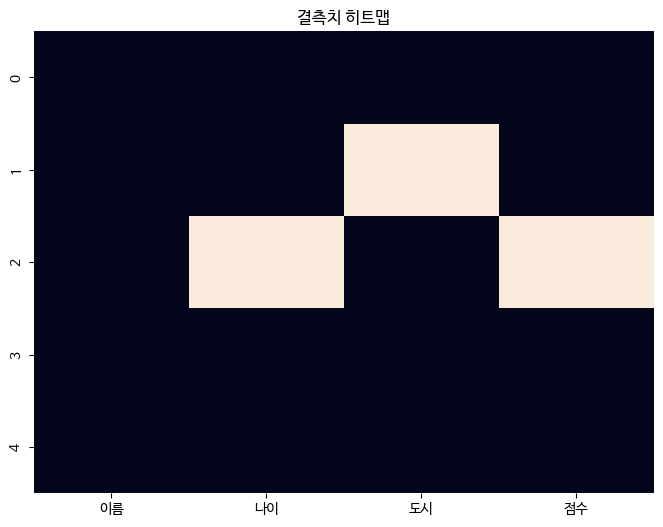

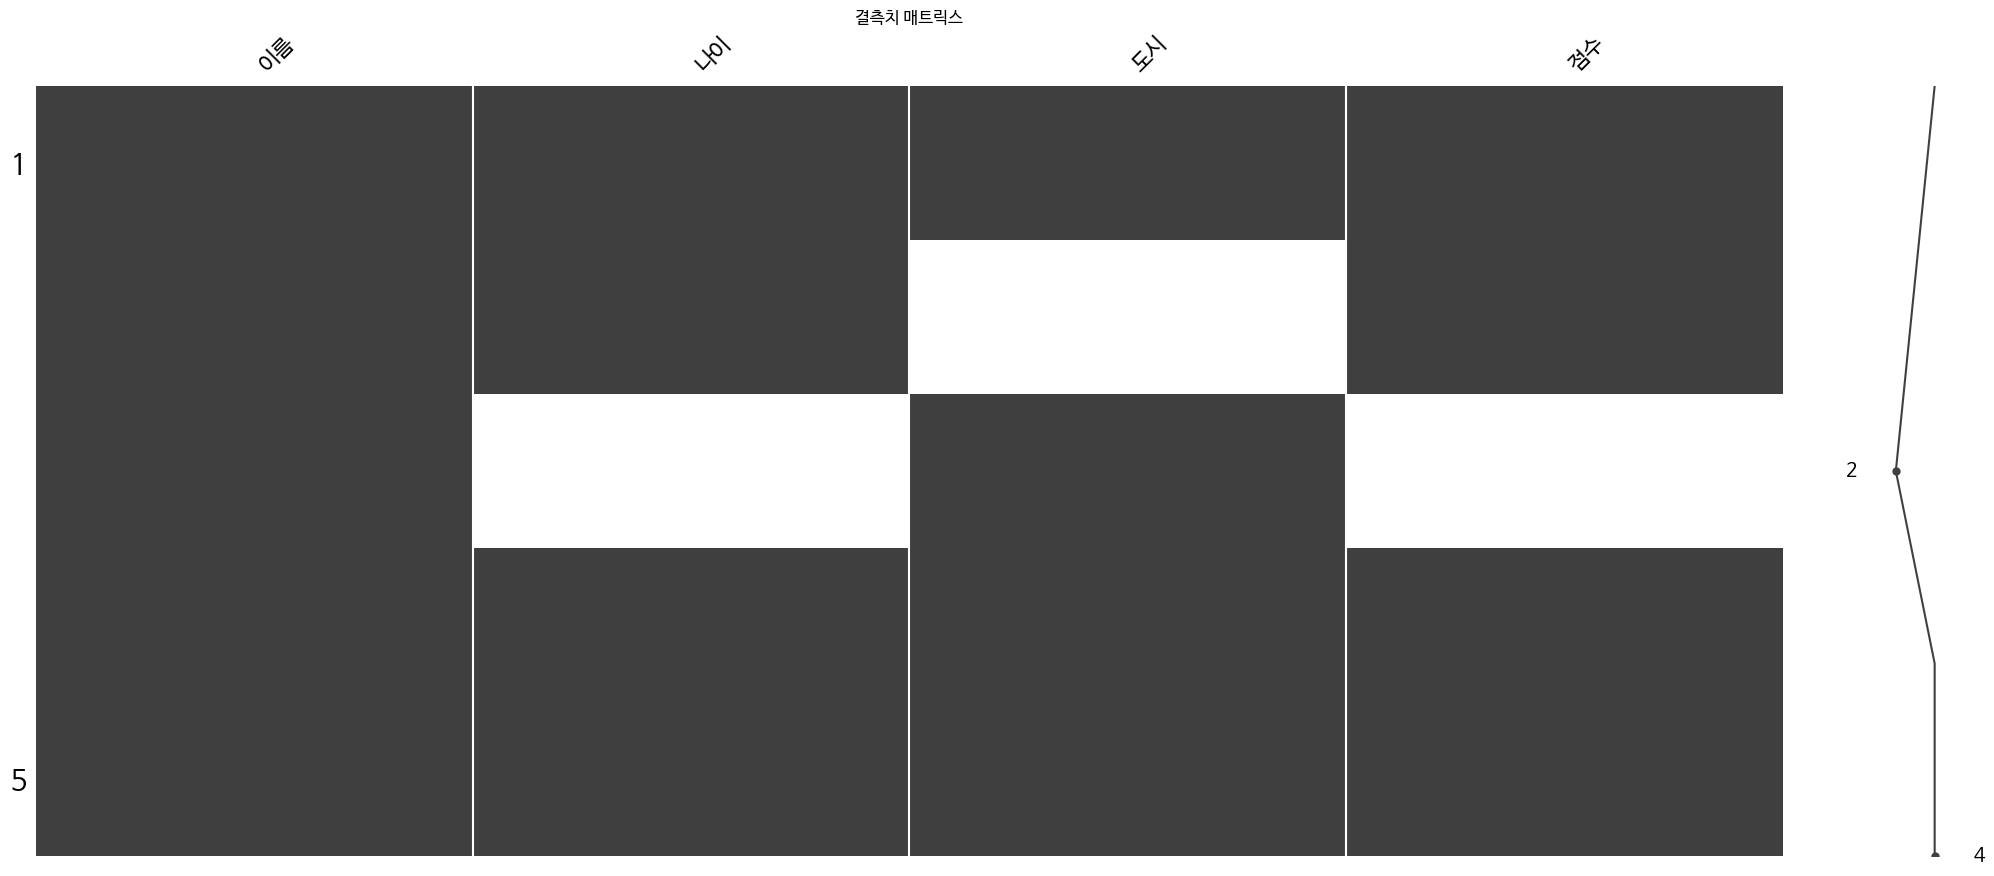

In [4]:
import numpy as np
import pandas as pd

### 시각화 라이브러리 임포트
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

data = {'이름': ['김철수', '이영희', '박민수', '최지훈', '정소희'],
        '나이': [25, 30, np.nan, 22, 35],
        '도시': ['서울', None, '인천', '서울', '대전'],
        '점수': [90, 85, np.nan, 80, 92]}
df = pd.DataFrame(data)

### 결측치 히트맵
plt.figure(figsize=(8, 6))
sns.heatmap(df.isnull(), cbar=False)
plt.title("결측치 히트맵")
plt.show()

### 결측치 매트릭스
msno.matrix(df)
plt.title("결측치 매트릭스")
plt.show()

### 7-3 사분위 범위를 통한 이상치 찾기

In [6]:
import pandas as pd
import numpy as np

점수_데이터 = [72, 68, 75, 282, 64, 31, 78, 69, 88, 92, 22, 84, 61, -90, 130, 66]
학번_데이터 = list(range(1001, 1001 + len(점수_데이터)))

df = pd.DataFrame({
    '학번': 학번_데이터,
    '점수': 점수_데이터
})

### 사분위 범위 경계값 계산
q1 = df['점수'].quantile(0.25)
q3 = df['점수'].quantile(0.75)
iqr = q3 - q1
하한값 = q1  - 1.5 * iqr
상한값 = q3 + 1.5 * iqr


### IQR 통계량 출력

print(q1, q3, iqr, 하한값, 상한값)



63.25 85.0 21.75 30.625 117.625


### 7-4 Z-점수를 통한 이상치 찾기

In [11]:
import pandas as pd
import numpy as np

점수_데이터 = [72, 68, 75, 282, 64, 31, 78, 69, 88, 92, 22, 84, 61, -90, 130, 66]
학번_데이터 = list(range(1001, 1001 + len(점수_데이터)))

df = pd.DataFrame({
    '학번': 학번_데이터,
    '점수': 점수_데이터
})

### Z-점수 계산
점수_평균 = df['점수'].mean()
점수_표준편차 = df['점수'].std()
df['점수_Z'] = (df['점수']-점수_평균) / 점수_표준편차
df

### 임계값 설정 및 이상치 여부 판단
임계값 = 2
df['이상치여부'] = df['점수_Z'].abs() > 임계값
df

### 이상치 데이터 출력
df[df['이상치여부']]

### 이상치 비율 출력
print(df['이상치여부'].mean())

0.125


### 7-5 평균값 및 선형보간법을 통한 결측치 처리

In [37]:
import pandas as pd
import numpy as np

df = pd.read_csv("/content/raw_large_shopping_customer.csv", engine='python')
print(df.isnull().sum())
print("---")
print(df.describe())

print("---")
df_cleaned = df.dropna(thresh=df.shape[1] - 1)
print("---")
print(df_cleaned.isnull().sum())
### 나이, 소득 평균값 대치 및 결과 출력
df_cleaned.loc[:, ['나이', '소득']].fillna(df_cleaned[['나이', '소득']].mean())

### 지출, 평균구매횟수 선형보간법 적용
df_cleaned.loc[:, ['지출', '평균구매횟수']] = df_cleaned[['지출', '평균구매횟수']].interpolate(method='linear')
print("---")
print(df_cleaned.describe())

df_cleaned.to_csv("cleaned_large_shopping_customer.csv", index=False, encoding="utf-8-sig")

ID         0
나이        50
소득        50
지출        50
평균구매횟수    50
dtype: int64
---
               ID          나이           소득           지출      평균구매횟수
count  500.000000  450.000000   450.000000   450.000000  450.000000
mean   250.500000   44.197778  6046.215556  3790.960000    5.629132
std    144.481833   15.156452  2206.654031  1832.348167    2.641199
min      1.000000   18.000000  2009.000000   503.000000    1.002138
25%    125.750000   32.000000  4153.000000  2406.500000    3.379487
50%    250.500000   45.000000  6093.000000  3720.000000    5.713978
75%    375.250000   57.000000  7776.500000  5406.250000    7.892348
max    500.000000   69.000000  9939.000000  6993.000000    9.994181
---
---
ID         0
나이        33
소득        38
지출        34
평균구매횟수    40
dtype: int64
---
               ID          나이           소득           지출      평균구매횟수
count  474.000000  441.000000   436.000000   474.000000  474.000000
mean   249.605485   44.190476  6024.883028  3779.394515    5.619551
std    144.5

### 7-6 DataFrame 값 변경

In [56]:
import pandas as pd

# 한글 환경에서 print(df) 시 줄 맞춤을 강제하는 옵션
pd.set_option('display.unicode.east_asian_width', True)

# (선택) 열이 잘리지 않고 다 나오도록 설정
pd.set_option('display.max_columns', None)

data = {'age': [25, 30, None, 22, 35],
        'city': ['Seoul', None, 'Incheon', 'Seoul', 'Daejeon'],
        'score': [90, 85, None, 80, 92]}
df = pd.DataFrame(data)

### replace를 이용한 Seoul -> 서울
df['city'] = df['city'].replace('Seoul','서울')
print(df)

### replace를 이용한 None -> 미정, Incheon -> 인천
df['city'] = df['city'].replace({None:'미정', 'Incheon':'인천'})
print('---')
print(df)
### map을 이용한 값 변경
df = pd.DataFrame(data)
city_map = {'Seoul': '서울특별시', None: '미정', 'Incheon':'인천광역시', 'Daejeon':'대전광역시'}
df['city'] = df['city'].map(city_map)
print('---')
print(df)
## map 은 함수를 넣을 수도 있다.
# lambda x 는 한줄함수 만들기

### apply 함수를 이용한 값 변경
df['age_str']=df['age'].map(lambda x: f" {x}살" if pd.notna(x) else "알수없음")
# pandas.notna(x)는 데이터에 결측치(NaN, None, NaT 등)가 없는지 확인하여 있으면 False,
# 없으면 True를 반환하는 함수입니다. isna()나 isnull()의 완전히 반대(부정) 역할을 하는 함수
print('---')
print(df.head())

### apply 함수를 이용한 행단위 값 변경
def age_plus_score(row):
    age = row['age'] if pd.notna(row['age']) else 0
    score = row['score'] if pd.notna(row['score']) else 0
    return age+score
df['age_plus_score']=df.apply(age_plus_score, axis=1)
print('---')
print(df.head())

### loc 인덱스를 이용한 값 변경
df.loc[df['score'] < 90, 'score'] = 90
print("\n점수가 90점 미만인 사람 90점으로 변경 :\n",df)

### where 함수를 이용한 값 변경
df['age_where'] = df['age'].where(df['age']>=30, other=0)
print("\nage가 30이상인 값만 유지하고 나머지를 0으로 변경\n", df['age_where'])


    age     city  score
0  25.0     서울   90.0
1  30.0     None   85.0
2   NaN  Incheon    NaN
3  22.0     서울   80.0
4  35.0  Daejeon   92.0
---
    age     city  score
0  25.0     서울   90.0
1  30.0     미정   85.0
2   NaN     인천    NaN
3  22.0     서울   80.0
4  35.0  Daejeon   92.0
---
    age        city  score
0  25.0  서울특별시   90.0
1  30.0        미정   85.0
2   NaN  인천광역시    NaN
3  22.0  서울특별시   80.0
4  35.0  대전광역시   92.0
---
    age        city  score   age_str
0  25.0  서울특별시   90.0    25.0살
1  30.0        미정   85.0    30.0살
2   NaN  인천광역시    NaN  알수없음
3  22.0  서울특별시   80.0    22.0살
4  35.0  대전광역시   92.0    35.0살
---
    age        city  score   age_str  age_plus_score
0  25.0  서울특별시   90.0    25.0살           115.0
1  30.0        미정   85.0    30.0살           115.0
2   NaN  인천광역시    NaN  알수없음             0.0
3  22.0  서울특별시   80.0    22.0살           102.0
4  35.0  대전광역시   92.0    35.0살           127.0

점수가 90점 미만인 사람 90점으로 변경 :
     age        city  score   age_str  age_plus_score
0  25.0

### 7-7 날짜 데이터 타입 다루기


In [61]:
import pandas as pd
date_str = ['2025-07-01', '2025-08-01', '2025-09-01']
df_date = pd.DataFrame({'date_str':date_str})

### datetime 타입 변환
df_date['date'] = pd.to_datetime(df_date['date_str'])

### 날짜 데이터 분리
print(df_date['date'].dt.year)
print(df_date['date'].dt.month)
print(df_date['date'].dt.day)
print(df_date['date'].dt.day_name())
### 날짜 데이터 포멧 변경

df_date['date_formatted']=df_date['date'].dt.strftime('%Y/%m/%d')
df_date

0    2025
1    2025
2    2025
Name: date, dtype: int32
0    7
1    8
2    9
Name: date, dtype: int32
0    1
1    1
2    1
Name: date, dtype: int32
0    Tuesday
1     Friday
2     Monday
Name: date, dtype: object


,date_str,date,date_formatted
0,2025-07-01,2025-07-01,2025/07/01
1,2025-08-01,2025-08-01,2025/08/01
2,2025-09-01,2025-09-01,2025/09/01


## 7-8 실습 시나리오 - 데이터 정제

### [재수행] 6-5 실습 시나리오 - Kaggle을 활용한 데이터 수집 및 측정

### 데이터 분포 시각화

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(train['sales'], bins=50)
plt.title("판매량 분포")
plt.xlabel("판매량")
plt.ylabel("빈도")
plt.xlim(0, 5000)
plt.show()

store_sales = train.groupby('store_nbr')['sales'].mean().reset_index()
plt.figure(figsize=(12, 6))
sns.barplot(x='store_nbr', y='sales', data=store_sales)
plt.title("매장별 평균 판매량")
plt.xlabel("매장 번호")
plt.ylabel("평균 판매량")
plt.xticks(rotation=90)
plt.show()

### 결측치 처리

In [72]:
print(train.isnull().sum())
print(stores.isnull().sum())
print(transactions.isnull().sum())
print(oil.isnull().sum())
holidays_events = holidats_events
print(holidays_events.isnull().sum())

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64
store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64
date            0
store_nbr       0
transactions    0
dtype: int64
date           0
dcoilwtico    43
dtype: int64
date           0
type           0
locale         0
locale_name    0
description    0
transferred    0
dtype: int64


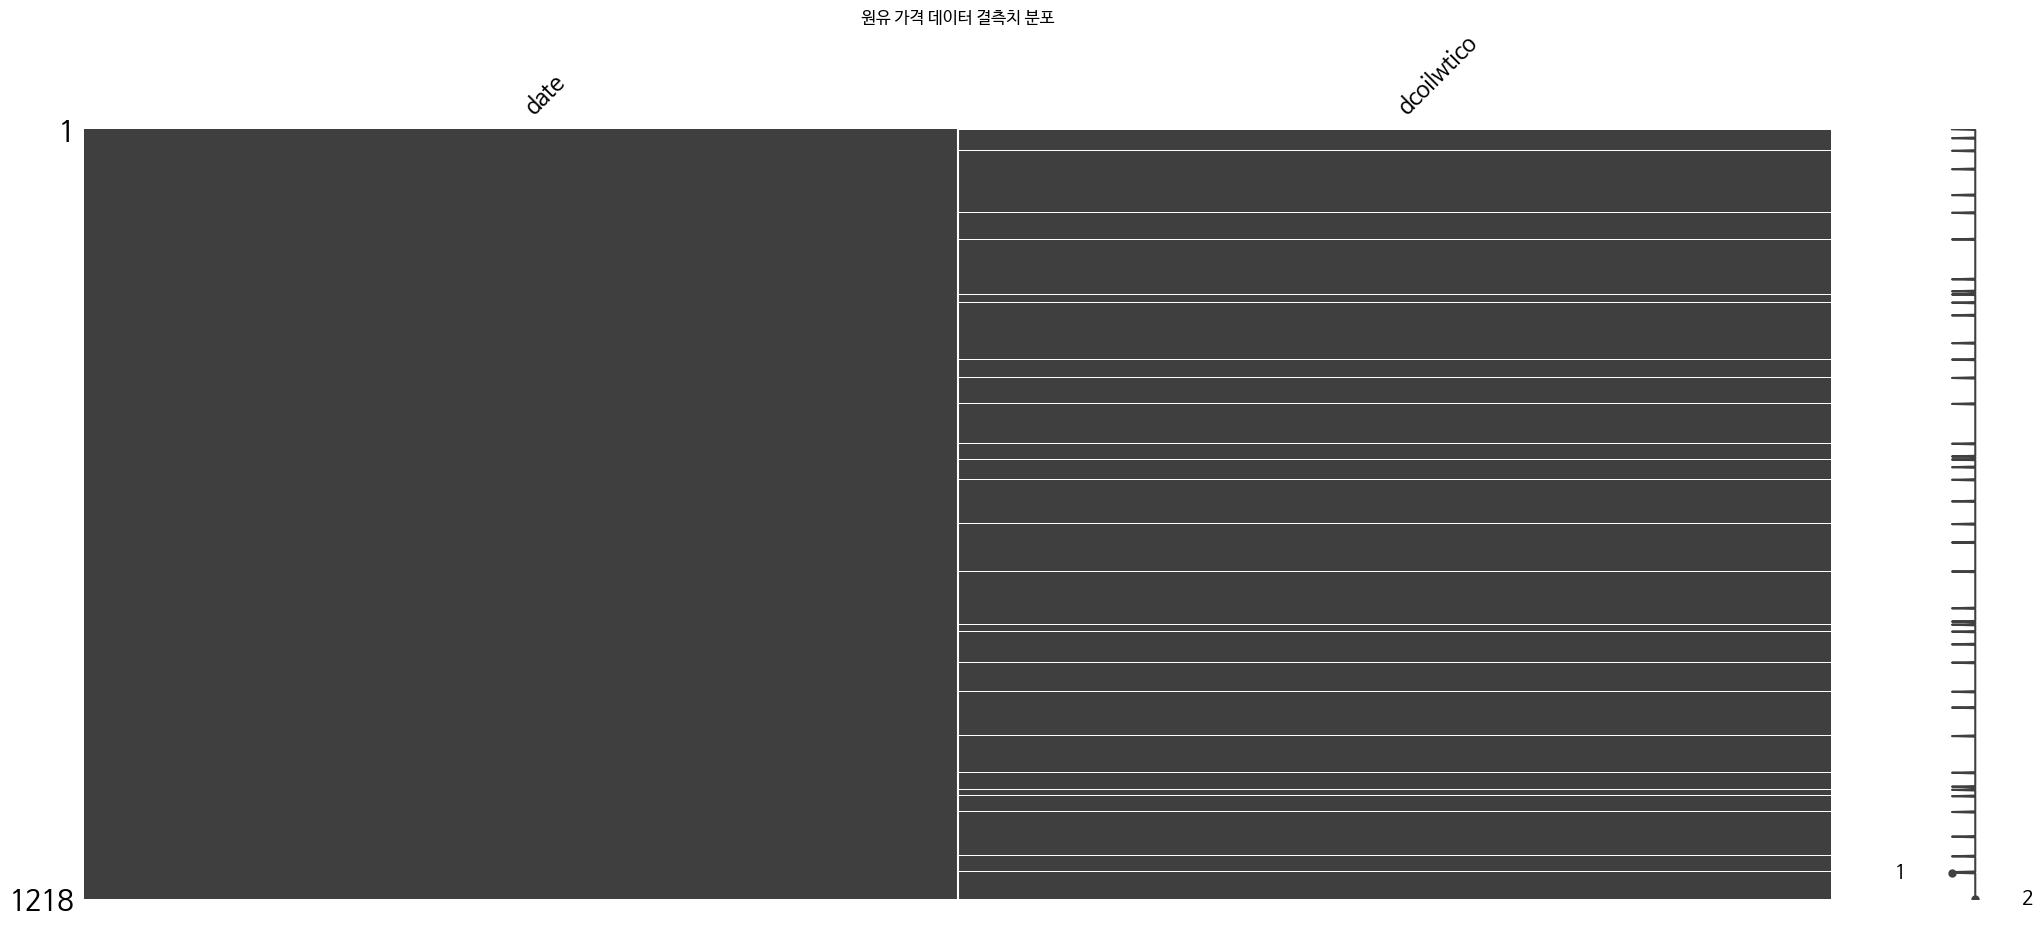

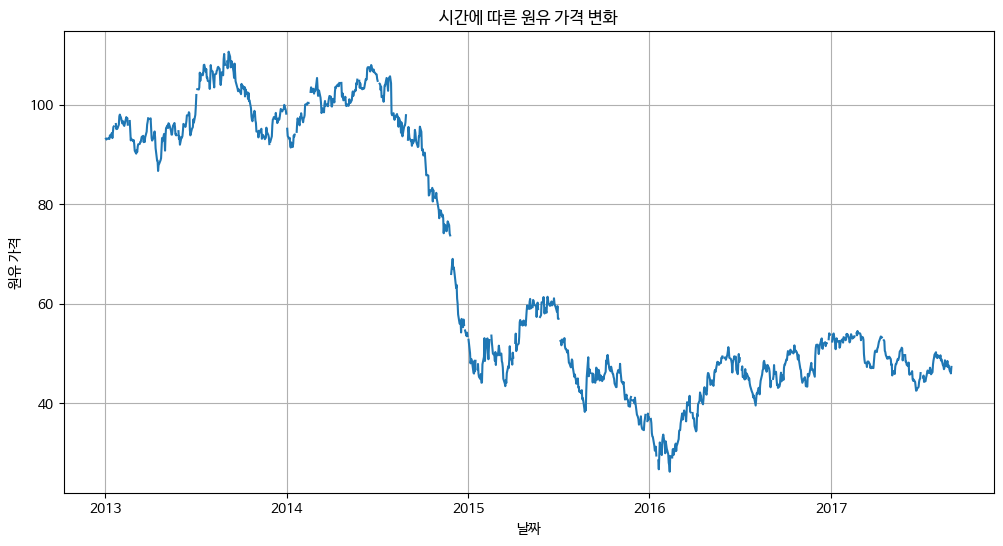

In [73]:
import missingno as msno

msno.matrix(oil)
plt.title("원유 가격 데이터 결측치 분포")
plt.show()

oil['date'] = pd.to_datetime(oil['date'])
plt.figure(figsize=(12, 6))
plt.plot(oil['date'], oil['dcoilwtico'])
plt.title("시간에 따른 원유 가격 변화")
plt.xlabel("날짜")
plt.ylabel("원유 가격")
plt.grid(True)
plt.show()

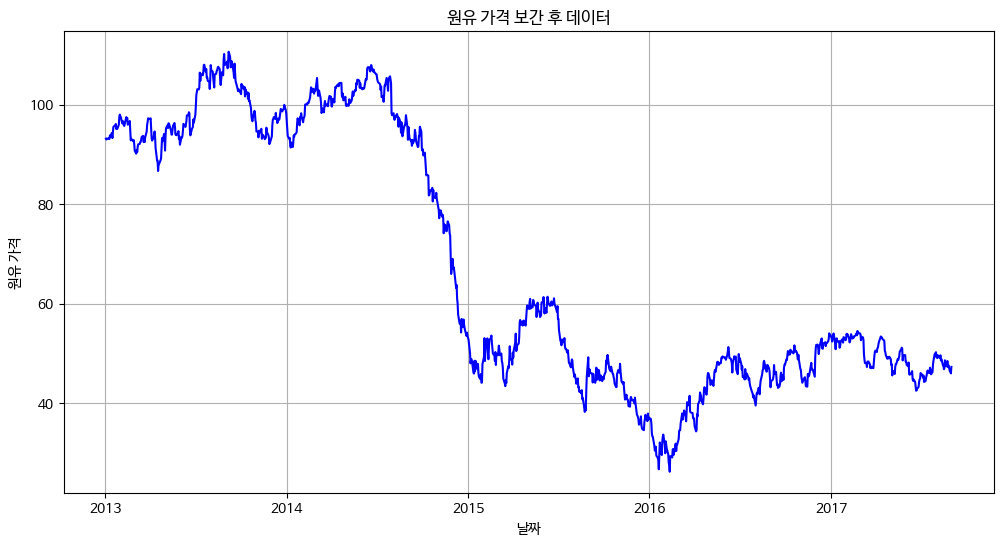

In [74]:
oil_cleaned = oil.copy()

### 선형 보간법 적용한 원유 가격 데이터
oil_cleaned['dcoilwtico'] = oil_cleaned['dcoilwtico'].interpolate(method='linear')

plt.figure(figsize=(12, 6))
plt.plot(oil_cleaned['date'], oil_cleaned['dcoilwtico'], 'b-')
plt.title("원유 가격 보간 후 데이터")
plt.xlabel("날짜")
plt.ylabel("원유 가격")
plt.grid(True)
plt.show()

### 이상치 처리

이상치 개수: 200,274건
전체 대비 비율: 6.67%


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


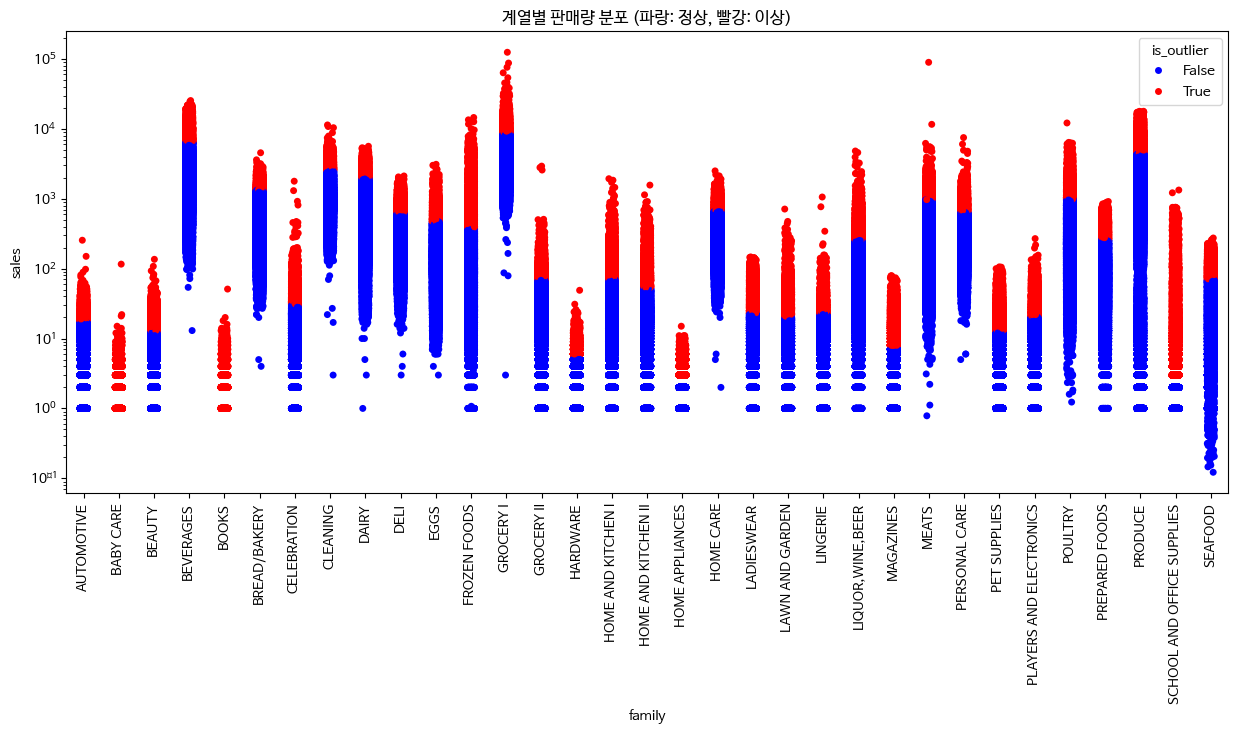

In [77]:
### 제품 계열별 판매 데이터 IQR 계산
family_bounds = train.groupby('family')['sales'].apply(
    lambda x : x.quantile(0.75) + 1.5 * (x.quantile(0.75) - x.quantile(0.25))
)

### 상한값 초과 판매량 이상치 분류
train_enhanced = train.copy()
train_enhanced['upper_bound'] = train_enhanced['family'].map(family_bounds)
train_enhanced['is_outlier'] = train_enhanced['sales'] > train_enhanced['upper_bound']

total_outliers = train_enhanced['is_outlier'].sum()
total_ratio = train_enhanced['is_outlier'].mean()

print(f"이상치 개수: {total_outliers:,}건")
print(f"전체 대비 비율: {total_ratio:.2%}")

plt.figure(figsize=(15,6))
sns.stripplot(x='family', y='sales', hue=train_enhanced['is_outlier'],
              data=train_enhanced, palette={False:'blue', True:'red'})
plt.xticks(rotation=90)
plt.yscale('log')
plt.title('계열별 판매량 분포 (파랑: 정상, 빨강: 이상)')
plt.show()

In [81]:


### 판매량이 상한값 초과 시, 판매량으로 상한값으로 대체
train_cleaned  = train.copy()
train_cleaned.loc[train_enhanced['is_outlier'], 'sales']  = train_enhanced.loc[train_enhanced['is_outlier'], 'upper_bound']

changed_count = (train['sales'] != train_cleaned ['sales']).sum()
print(f"대체된 데이터 수: {changed_count}건")

대체된 데이터 수: 200274건


### 날짜 데이터 처리

In [84]:
### 판매, 거래, 휴일 이벤트, 원율 데이터 내 date 컬럼 데이터 datetime 데이터 타입으로 변경
train_cleaned['date']=pd.to_datetime(train_cleaned['date'])
transactions['date']=pd.to_datetime(transactions['date'])
holidays_events['date']=pd.to_datetime(holidays_events['date'])
oil_cleaned['date']=pd.to_datetime(oil_cleaned['date'])

train_cleaned['year'] = train_cleaned['date'].dt.year
train_cleaned['month'] = train_cleaned['date'].dt.month
train_cleaned['day'] = train_cleaned['date'].dt.day
train_cleaned['dayofweek'] = train_cleaned['date'].dt.dayofweek
### 주말, 월초, 월말 여부 추철

train_cleaned['weekend'] = train_cleaned['dayofweek'].apply(lambda x: 1 if x>=5 else 0)
train_cleaned['is_month_start'] = train_cleaned['date'].dt.is_month_start
train_cleaned['is_month_end'] = train_cleaned['date'].dt.is_month_end

print("날짜 특성 추출 결과:")
print(train_cleaned[['date', 'year', 'month', 'day', 'dayofweek', 'weekend', 'is_month_start', 'is_month_end']].head())

날짜 특성 추출 결과:
        date  year  month  day  dayofweek  weekend  is_month_start  \
0 2013-01-01  2013      1    1          1        0            True   
1 2013-01-01  2013      1    1          1        0            True   
2 2013-01-01  2013      1    1          1        0            True   
3 2013-01-01  2013      1    1          1        0            True   
4 2013-01-01  2013      1    1          1        0            True   

   is_month_end  
0         False  
1         False  
2         False  
3         False  
4         False  


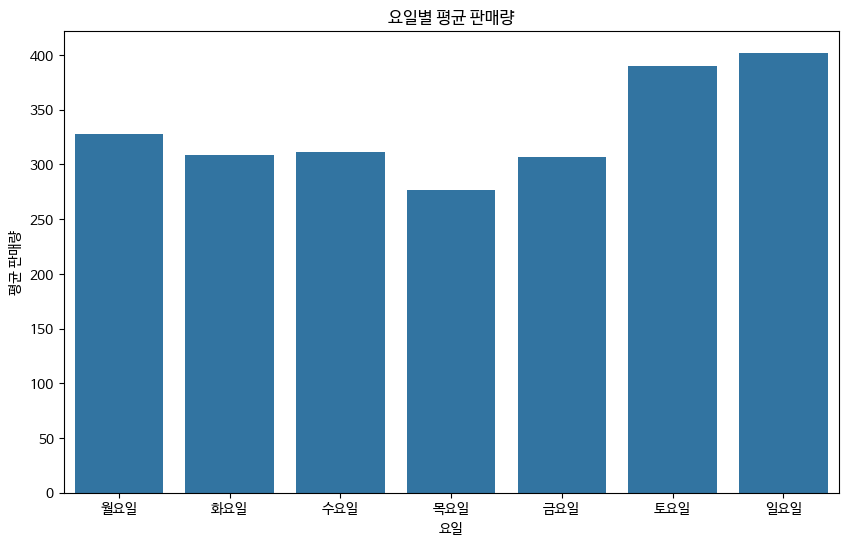

In [85]:
## 요일별 평균 판매량을 계산
day_sales = train_cleaned.groupby('dayofweek')['sales'].mean().reset_index()
day_sales['day_name'] = day_sales['dayofweek'].map({ 0: '월요일', 1: '화요일', 2: '수요일', 3: '목요일', 4: '금요일', 5: '토요일', 6: '일요일' })
## 요일 출력값 변경

plt.figure(figsize=(10, 6))
sns.barplot(x='day_name', y='sales', data=day_sales)
plt.title("요일별 평균 판매량")
plt.xlabel("요일")
plt.ylabel("평균 판매량")
plt.show()

### 데이터 통합

In [88]:
## 판매, 거래 데이터 통합
train_with_trans = pd.merge(
    train_cleaned, transactions,
    on = ['date', 'store_nbr'],
    how='left'
)


## 매장 데이터 통합
train_with_store = pd.merge(
    train_with_trans, stores,
    on=['store_nbr'],
    how='left'
)

## 원유 데이터 통합
train_final = pd.merge(
    train_with_store, oil_cleaned,
    on=['date'],
    how='left'
)


print("최종 데이터셋 정보:")
print(f"행 개수: {train_final.shape[0]}, 열 개수: {train_final.shape[1]}")
print(train_final.columns.tolist())
print(train_final.head())

train_final.to_csv("train_final.csv", index=False, encoding="utf-8-sig")

최종 데이터셋 정보:
행 개수: 3000888, 열 개수: 19
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion', 'year', 'month', 'day', 'dayofweek', 'weekend', 'is_month_start', 'is_month_end', 'transactions', 'city', 'state', 'type', 'cluster', 'dcoilwtico']
   id       date  store_nbr      family  sales  onpromotion  year  month  day  \
0   0 2013-01-01          1  AUTOMOTIVE    0.0            0  2013      1    1   
1   1 2013-01-01          1   BABY CARE    0.0            0  2013      1    1   
2   2 2013-01-01          1      BEAUTY    0.0            0  2013      1    1   
3   3 2013-01-01          1   BEVERAGES    0.0            0  2013      1    1   
4   4 2013-01-01          1       BOOKS    0.0            0  2013      1    1   

   dayofweek  weekend  is_month_start  is_month_end  transactions   city  \
0          1        0            True         False           NaN  Quito   
1          1        0            True         False           NaN  Quito   
2          1        0            True  